📊 ۱. بررسی کیفیت داده‌ها (Data Quality Audit)
• ابعاد جدول امتیازها: 24 ردیف و 5 ستون
• ابعاد جدول آیتم‌ها:    8 ردیف و 5 ستون
• مقادیر گمشده در امتیازها: 0
• مقادیر گمشده در آیتم‌ها:    0
• ردیف‌های تکراری:         0

• نوع داده‌های ستون‌ها (dtypes):
user_id        str
item_id        str
item_type      str
rating       int64
timestamp    int64
dtype: object

📈 ۲. آمار توصیفی نمرات (Descriptive Statistics)
count    24.00
mean      3.96
std       1.04
min       2.00
25%       3.00
50%       4.00
75%       5.00
max       5.00
------------------------------------------------------------
میانگین (Mean): 3.96 | واریانس (Variance): 1.09 | انحراف معیار (Std): 1.04 | میانه (Median): 4.00

🎯 ۳. نتایج سؤالات تحلیلی EDA
• میانگین و انحراف معیار نمرات به تفکیک رسانه:
           count  mean   std
item_type                   
book          11  4.00  1.00
movie         13  3.92  1.12

• درصد نمرات ثبت‌شده بالاتر یا مساوی ۴: 70.8%
• میانگین تعداد امتیاز ثبت‌شده به ازای هر کاربر: 4.0

✅ فایل نمودار تحل

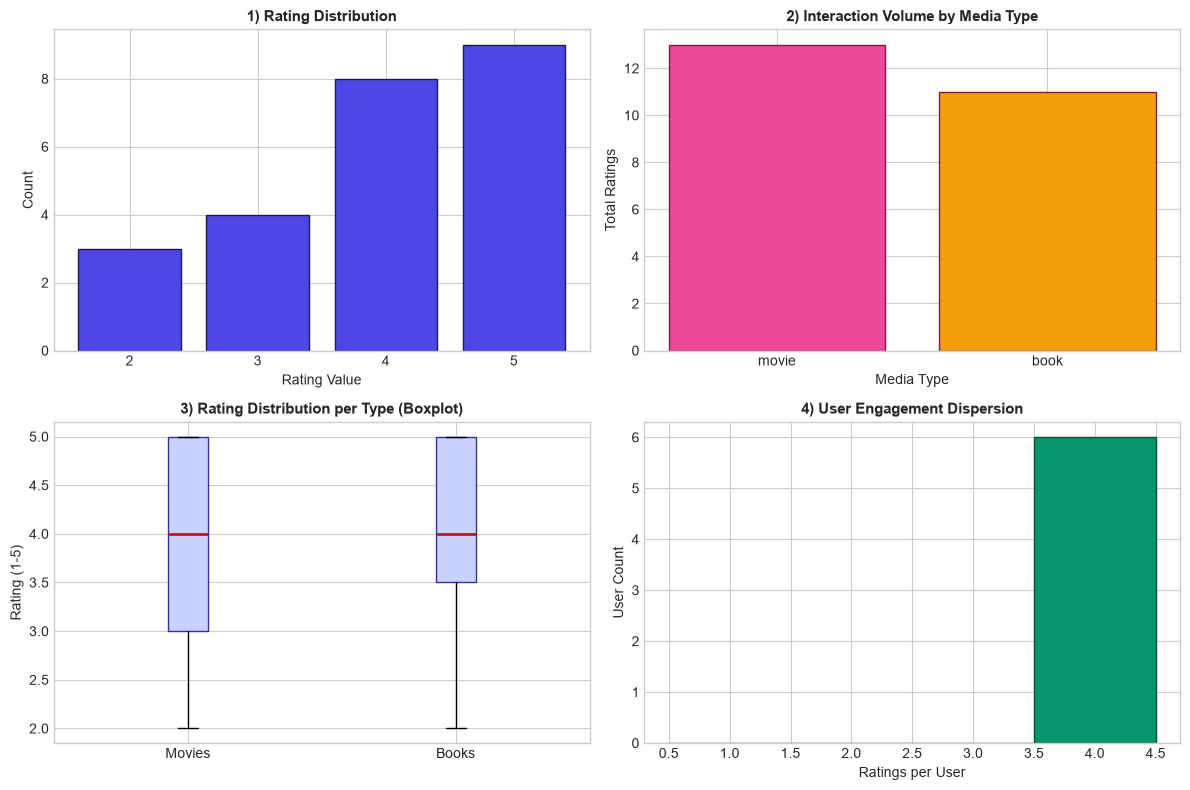

In [3]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_dir = Path("../data")
ratings_path = data_dir / "ratings.csv"
items_path = data_dir / "items.csv"

df_ratings = pd.read_csv(ratings_path)
df_items = pd.read_csv(items_path)
df_merged = pd.merge(df_ratings, df_items, on="item_id")

print("=" * 60)
print("📊 ۱. بررسی کیفیت داده‌ها (Data Quality Audit)")
print("=" * 60)
print(f"• ابعاد جدول امتیازها: {df_ratings.shape[0]} ردیف و {df_ratings.shape[1]} ستون")
print(f"• ابعاد جدول آیتم‌ها:    {df_items.shape[0]} ردیف و {df_items.shape[1]} ستون")
print(f"• مقادیر گمشده در امتیازها: {df_ratings.isna().sum().sum()}")
print(f"• مقادیر گمشده در آیتم‌ها:    {df_items.isna().sum().sum()}")
print(f"• ردیف‌های تکراری:         {df_ratings.duplicated().sum()}")
print("\n• نوع داده‌های ستون‌ها (dtypes):")
print(df_ratings.dtypes)

print("\n" + "=" * 60)
print("📈 ۲. آمار توصیفی نمرات (Descriptive Statistics)")
print("=" * 60)
x = df_ratings["rating"]
print(x.describe().round(2).to_string())
print("-" * 60)
print(f"میانگین (Mean): {x.mean():.2f} | واریانس (Variance): {x.var():.2f} | انحراف معیار (Std): {x.std():.2f} | میانه (Median): {x.median():.2f}")

print("\n" + "=" * 60)
print("🎯 ۳. نتایج سؤالات تحلیلی EDA")
print("=" * 60)
avg_by_type = df_merged.groupby("item_type")["rating"].agg(["count", "mean", "std"]).round(2)
print("• میانگین و انحراف معیار نمرات به تفکیک رسانه:")
print(avg_by_type)

high_ratings_pct = (df_ratings["rating"] >= 4).mean() * 100
print(f"\n• درصد نمرات ثبت‌شده بالاتر یا مساوی ۴: {high_ratings_pct:.1f}%")

users_activity = df_ratings["user_id"].value_counts()
print(f"• میانگین تعداد امتیاز ثبت‌شده به ازای هر کاربر: {users_activity.mean():.1f}")

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

rating_counts = df_merged["rating"].value_counts().sort_index()
axes[0, 0].bar(rating_counts.index.astype(str), rating_counts.values, color="#4f46e5", edgecolor="#1e1b4b")
axes[0, 0].set_title("1) Rating Distribution", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Rating Value")
axes[0, 0].set_ylabel("Count")

type_counts = df_merged["item_type"].value_counts()
axes[0, 1].bar(type_counts.index, type_counts.values, color=["#ec4899", "#f59e0b"], edgecolor="#831843")
axes[0, 1].set_title("2) Interaction Volume by Media Type", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Media Type")
axes[0, 1].set_ylabel("Total Ratings")

box_data = [df_merged[df_merged["item_type"] == "movie"]["rating"],
            df_merged[df_merged["item_type"] == "book"]["rating"]]
axes[1, 0].boxplot(box_data, patch_artist=True,
                   boxprops=dict(facecolor="#c7d2fe", color="#3730a3"),
                   medianprops=dict(color="#b91c1c", linewidth=2))
axes[1, 0].set_xticks([1, 2])
axes[1, 0].set_xticklabels(["Movies", "Books"])
axes[1, 0].set_title("3) Rating Distribution per Type (Boxplot)", fontsize=11, fontweight="bold")
axes[1, 0].set_ylabel("Rating (1-5)")

user_activity = df_merged["user_id"].value_counts()
axes[1, 1].hist(user_activity.values, bins=range(1, user_activity.max() + 2), 
                color="#059669", edgecolor="#064e3b", align="left")
axes[1, 1].set_title("4) User Engagement Dispersion", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Ratings per User")
axes[1, 1].set_ylabel("User Count")

plt.tight_layout()

output_chart = data_dir / "eda_analysis.png"
plt.savefig(output_chart, dpi=300, bbox_inches='tight')
print("\n" + "=" * 60)
print(f"✅ فایل نمودار تحلیلی با موفقیت ذخیره شد در:\n{output_chart.resolve()}")
print("=" * 60)

plt.show()